# BeamNG drifting Deep RL

> #### AI usage disclaimer
> I have used AI (chat) for small portions of this notebook such as the BEV height map and the investigation into how to obtain the in-game drift score  
> For everything the AI did, I've refined it and spent the time necessary to understand and explain it more clearly from my point of view  
> There are no statements made by AI

## Introduction
This notebook is a walkthrough of BeamNG.tech and BeamNGpy functionality and data, general information about Deep RL which will help to train an AI to drift.

Also be sure to study the complete documentation of [BeamNGpy](https://documentation.beamng.com/api/beamngpy/) and [BeamNG.tech](https://documentation.beamng.com/beamng_tech/), if you want to familiarize yourself more with the library.

What I personally found very helpful was to check the jupyter notebooks in ./beamngpy/examples. Many things were simply copied from there, the examples provide ample context so if you can't understand how something here works, grep for a related term across those notebooks and there's a high chance it will become clearer.

I learned about jupyter notebooks just now starting this project, they're more useful than a book because they allow you to run shell commands and python code via a socket (keeping python context) from the computer that hosts the jupyter notebooks (can be a remote server too!)

You can host jupyter notebooks by changing to the dir containing the notebooks, then running:

```bash
BNG_HOME=/path/to/BeamNG.tech.v0.39.4.0 jupyter notebook
```

`BNG_HOME` needs to point to the folder where you extracted BeamNG.tech, for the code written here to run correctly. 

Let's start!

## Where do we start?

As a developer I've actively avoided math and the topic of AI wasn't interesting to me as it seemed heavily math based, which pure AI is, but we're not actually going to invent new math formulas here (new training methods / architectures, etc.), we're simply aiming to build on top of work and research already done while having fun - building an AI that can drift in BeamNG.

> Before we even start with this, I considered it is important to mention that the choices for the AI's architecture require at least some knowledge of the theory behind deep reinforcement learning. Where choices are made, I'll highlight what led to those choices and supporting materials for more information.

In this introduction though, we'll mostly focus on what BeamNG provides and what we can use from it, only making the promised references attached to choices, revisiting with more details in the next notebooks.

### Getting started

These are the imports we'll need for this walkthrough

In [1]:
import colorsys
import time
import random
import json
import os
import glob
import tempfile
import cv2
import matplotlib.pyplot as plt
import numpy as np
from beamngpy import BeamNGpy, Scenario, Vehicle
from beamngpy.sensors import (
    Camera,
    AdvancedIMU,
    Damage,
    Electrics,
    Lidar,
    State,
    Timer,
    Ultrasonic,
    RoadsSensor,
)
from IPython.display import clear_output

To start BeamNG.tech using BeamNGpy, you use the constructor of the class `BeamNGpy`.  
The `BeamNGpy` instance allows you to control the simulation.  
We call `BeamNGpy.open()` to start the simulation which is connected to the Python process using a TCP socket.

In [4]:
beamng = BeamNGpy("localhost", 25252)
beamng.open()

The main menu of BeamNG.tech pops up and we are ready to set up the simulation!  
We will start on the `west_coast_usa` map. Let's generate a `Scenario` object, a single `Vehicle` and add the vehicle to the scenario.  
Notice that the `print` at the end appears when the game is actually ready to play, the commands are synchronous

In [5]:
scenario = Scenario("west_coast_usa", "beamngpy_feature_overview")
ego = Vehicle("ego", model="etki", part_config="drift", color="Grey")
scenario.make(beamng)
beamng.scenario.load(scenario)

waypoints = scenario.find_waypoints()
waypoints = {w.name: w for w in waypoints}

# In this example we hardcode the waypoint
key = "Bridge15_C"
print(f"teleported to {key} out of {len(waypoints.keys())} locations")

scenario.add_vehicle(
    ego, pos=waypoints[key].pos, rot_quat=waypoints[key].rot
)

beamng.scenario.start()
print("Scenario is started")

teleported to Bridge15_C out of 838 locations
Scenario is started


##### How do we spawn other cars?

Each car has a zip file, the zip filename without the extension represents the `model` argument for the `Vehicle` class init function.

In [41]:
!ls "$BNG_HOME"/content/vehicles/*.zip | tail -n 3
!ls "$BNG_HOME"/content/vehicles/*.zip | grep "pessima"

BeamNG.tech.v0.39.4.0//content/vehicles/wl40.zip
BeamNG.tech.v0.39.4.0//content/vehicles/woodcrate.zip
BeamNG.tech.v0.39.4.0//content/vehicles/woodplanks.zip
BeamNG.tech.v0.39.4.0//content/vehicles/pessima.zip


the `| tail -n 3` can be excluded to see all options  
a `| grep` (pipe to grep) can be used to filter the list by search terms.

> Notice that not all of these are cars

The default `part_config` in the `Vehicle` init function can be found by extracting the `info.json` file from the zip to standard output, then piping to grep to identify the json property `default_pc`

In [42]:
!unzip -p "$BNG_HOME"/content/vehicles/pessima.zip vehicles/pessima/info.json | grep "default_pc"

  "default_pc": "LX_M",


More `Vehicle` `part_config` options can also be obtained from the zip:

In [48]:
!unzip -l ./BeamNG.tech.v0.39.4.0/content/vehicles/pessima.zip *.pc | sed -n -r "s|.*/([^.]*)[.]pc|\1|p" | grep -A 2 -B 2 "drift"

custom2
derby
drift
DX_A
DX_M


With this information, we are ready to change the car, replacing the one already spawned

In [4]:
scenario.remove_vehicle(ego)
ego = Vehicle("alter ego", model="pessima", part_config="drift", color="Red")
scenario.add_vehicle(
    ego, pos=waypoints[key].pos, rot_quat=waypoints[key].rot
)

Other drift car setups (`model` / `part_config`):

- `bx` / `pro_drift_M`
- `bastion` / `drift`
- `etk800` / `858_drift_M`
- `etkc` / `kc8_drift_M`
- `etki` / `drift`
- `fullsize` / `drift`
- `sbr` / `drift`

Let's also select a random drift car from this set

In [4]:
DRIFT_CARS_6SPEED = [
    {"model": "bx", "part_config": "pro_drift_M"},
    {"model": "bastion", "part_config": "drift"},
    {"model": "etk800", "part_config": "858_drift_M"},
    {"model": "etkc", "part_config": "kc8_drift_M"},
    {"model": "etki", "part_config": "drift"},
    {"model": "fullsize", "part_config": "drift"},
    {"model": "sbr", "part_config": "drift"},
]

scenario.remove_vehicle(ego)

car = random.choice(DRIFT_CARS_6SPEED)

ego = Vehicle("ego", license="DRIFT", color="Red", **car)
scenario.add_vehicle(
    ego, pos=waypoints[key].pos, rot_quat=waypoints[key].rot
)

We could also move the car to a random starting location  
Teleports fix damage as a bonus, although I observed by testing that tires still appear visually damaged.

In [35]:
# This is a way to avoid tunnels:
#key = "tunnel"
#while "tunnel" in key:
    #key = random.choice(list(waypoints.keys()))

key = random.choice(list(waypoints.keys()))
print(f"teleported to {key} out of {len(waypoints.keys())} locations")

#print(waypoints[key].__dict__)

ego.teleport(
    waypoints[key].pos, rot_quat=waypoints[key].rot
)

teleported to tunnel_NE_A_27 out of 838 locations


True

### The goal

At this point we have the basics: a drift car, placed on the street. How do we get from here to a self-driving car that drifts?  

#### Big picture
Now the big picture is important to mention, and it is very well explained in this [HuggingFace Deep RL course](https://huggingface.co/learn/deep-rl-course/unit1/what-is-rl). The main point is that AI learns just like humans do, by experimenting, and the example given there is of a child learning to play a video game. (I still recommend going through that course fully, you will get an even better understanding)

So games place the AI / child in an environment where actions can be made that change the state of the game (level progression) and can lead to rewards / dopamine (passing the level) or an opposite, negative outcome (failing the level or losing progression, skill, health, etc). This will shape how the AI / child navigates the environment going forward, with _learned_ behaviors from past failures or successes, normally with a goal to increase rewards / dopamine.

#### How to reward drifting?

To teach an AI to drift, this means that we must shape the environment to reward drifting and to punish normal driving or staying still. This is the next step, but before we can achieve this, we have to think of how we build a reward function to shape the interaction to incentivise drifting, in order to map what the game can offer in this direction.

The first obvious option is to get the drift score - which is displayed on the screen when actually drifting.

Besides the drift score, let's just check what a drifter naturally observes as information while drifting.

Personally I consider:

- RPM (I hear it and it's displayed in the dashboard)
- Turbo pressure (there's usually a gauge)
- The car's travel direction (not to be confused with its front direction)
- IMU - rotation and G-forces (felt while driving)
- Gear (I sometimes move my hand to the shifter, observing it)
- Airspeed (I feel it, estimating via hearing and vision)
- The environment (street) - implies vision for crash avoidance, so drifts can be linked further, to extend the reward.

#### Anything else relevant?

There are other small but relevant details to consider about the environment. The choices made here will affect how much the AI will actually learn about drifting and how much of this information will be applicable to real environments (real cars).

We don't want the drifting to incorporate / be trained with any driving assists, these exist in some forms in real cars, but they're generally not found on drift cars, so we should disable driving assists.  
How the car will function is also important. We'd like the drifter to switch gears, just because how the game switches gears automatically doesn't really help drifting. The automatic clutch assist will be kept though, to ease the learning curve. We may experiment at a later point with the clutch defined as a possible action.

The `autoThrottle` setting in the game is described as RPM matching on gear shifts, which when missing can lead to engine damage in the chosen environment configuration, so we'll leave it on for now (we may walk this back together with the clutch action introduction).

When we'll train the AI, it is important that the environment is stable, fast and that it consumes few resources. There are a few methods to maximize these properties, which are explained later.

#### Back to the game

Let's disable the driving assists and set the game's resolution to something that (presumably) lowers the load on the GPU, while also allowing us to work with the game open and not taking as much screen space.

In [5]:
# Disable driving assists
beamng.queue_lua_command('''
settings.setValue("steeringAutocenterEnabled", false)
settings.setValue("steeringSlowdownEnabled", false)
settings.setValue("steeringStabilizationEnabled", false)
settings.setValue("steeringUndersteerReductionEnabled", false)
settings.setValue("steeringLimitEnabled", false)
settings.setValue("autoClutch", true)
settings.setValue("autoThrottle", true)
settings.setValue("absBehavior", "off")
''')

# Fixed windowed resolution
beamng.settings.change("GraphicDisplayMode", "Windowed")
beamng.settings.change("GraphicDisplayResolutions", "640 480")
beamng.settings.apply_graphics()

# realistic manual gearbox
ego.set_shift_mode("realistic_manual")

We can set the game's fps and set the game to [deterministic mode](https://documentation.beamng.com/beamng_tech/deterministic_mode/).

To speed up physics 2x, `factor` can be adjusted, if the physics can keep up - meaning if the CPU can process the physics this fast and the GPU can process 2x `fpsbase` realtime.

Adjust `factor` to speed up the physics.

Limitations (from BeamNG.tech docs):

> The factor is the upper limit of the speedup. If the framerate is lower than what is set in the frame limiter, the speedup will be lower than the factor.
20 / fpslimit * factor has to be an integer and fpslimit should be at least 20. Examples: For 2x speedup, this means the frame limiter has to be set to either 20 or 40. For 3x speedup, the possible values are 20, 30 and 60.

The following code should make the simulation twice as fast as realtime.  
To revert to normal, try setting `factor` to `1`

In [6]:
# -- set deterministic
beamng.queue_lua_command('be:setPhysicsDeterministic(true)')

# -- set to a value that your PC can handle and also 20 / fpslimit * factor has to be an integer
fpsbase = 20
# -- maximum speed up factor
factor = 2
fpslimit = int(factor * fpsbase)
beamng.queue_lua_command(f"settings.setValue('fpsLimit', {fpslimit})")

beamng.queue_lua_command('settings.setValue("fpsLimitEnabled", true)')
iterations = 20 / fpslimit * factor
beamng.queue_lua_command(f'be:setPhysicsSpeedFactor({iterations})')


To manually step frames, the simulation must be paused, then inside a loop the simulation can be stepped (like in a debugger)  
While this is possible, it's not really practical, because it slows the simulation, forcing it to sync with the python code - in my experience it's slow even for the simplest loops

As a visual indicator, this loop displays FPS while it runs (via `extensions.core_metrics.currentMode = *`)

This loop exemplifies it with a programatic drift - in my experience it is quite stable, on my computer.  
It drifts a right hand turn and spins around in front of the gas station entrance, properly aligned in the correct lane (with `fpsbase` 20 and `factor` 1).

I had fun writing it, to check how stable are the BeamNG physics and I am impressed with the performance.

The `ctrl_loop_hook` function will be useful later to check sensors.

In [7]:
scenario.remove_vehicle(ego)
ego = Vehicle("ego", model="bx", part_config="pro_drift_M", color="Red")
scenario.add_vehicle(
    ego, pos=waypoints[key].pos, rot_quat=waypoints[key].rot
)

def ctrl_loop_init():
    global ego
    key = "Bridge15_C"
    ego.teleport(
        waypoints[key].pos, rot_quat=waypoints[key].rot
    )
    time.sleep(1.05)
    # pause physics / time
    beamng.control.pause()

def ctrl_loop_hook():
    # will be useful later
    pass

def ctrl_loop():
    ctrl_loop_init()
    
    beamng.queue_lua_command('extensions.core_metrics.currentMode = 1')
    iterations=160
    ego.control(gear=1)
    for step in range (1,iterations):
        t=0.0; s=0.0; p=0.0
        if step > 0 and step < 40:
            t=0.4; s=0.3
        elif step < 55:
            t=1.0; s=-0.8
        elif step < 70:
            t=1.0; s=-0.5
        elif step < 80:
            t=0.5; s=-0.8;
        elif step < 95:
            t=0.55; s=-0.5;
        elif step < 110:
            p=0.8; s=-0.8;
        elif step < 120:
            s=0.4
        elif step < 125:
            t=0.8; s=-0.99;
        elif step >= 145:
            p=0.9; 
            ego.control(gear=0)
            
        ego.control(
            throttle=t, 
            steering=s, 
            parkingbrake=p
        )
        # advance exactly 1 frame (blocks until done)
        ctrl_loop_hook()
        beamng.control.step(1)

    ego.control(throttle=0.0, steering=0.0)
    beamng.queue_lua_command('extensions.core_metrics.currentMode = 0')
    beamng.control.resume()

ctrl_loop()

At this point we can set up some sensors, to identify how we will use the sensor data to shape our environment to reward drifting.

In [8]:
electrics = Electrics()
damage = Damage()
timer = Timer()

ego.sensors.attach("electrics", electrics)
ego.sensors.attach("damage", damage)
ego.sensors.attach("timer", timer)

imu = AdvancedIMU("imu", beamng, ego, gfx_update_time=0.01, is_send_immediately=True, is_dir_world_space=False)

roads = RoadsSensor("roads", beamng, ego, physics_update_time=0.02,
                            is_send_immediately=True)

Let's check the same loop from before but with data logging in the `ctrl_loop_hook`


Finished capturing data!


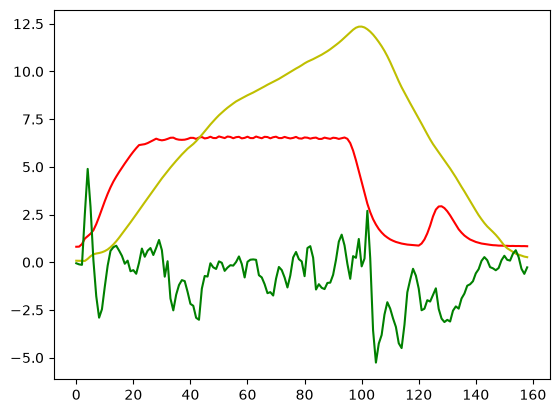

<Figure size 640x480 with 0 Axes>

In [56]:
rpms = list()
speeds = list()
imu_y = list()
sensors = ego.sensors

def ctrl_loop_init():
    global ego, electrics, damage, timer

    key = "Bridge15_C"
    ego.teleport(
        waypoints[key].pos, rot_quat=waypoints[key].rot
    )
    time.sleep(1)
    # pause physics / time
    beamng.control.pause()

def ctrl_loop_hook():
    global ego, sensors, rpms, speeds, imu_y
    ego.sensors.poll()
    positions.append(ego.state["pos"])
    directions.append(ego.state["dir"])
    imu_y.append(imu.poll()["accSmooth"][1])
    rpms.append(sensors["electrics"]["rpm"])
    speeds.append(sensors["electrics"]["airspeed"])

ctrl_loop()
print('\nFinished capturing data!')

# scaling for visibility
rpms = [x / 1000 for x in rpms]
boost = [x * 1000 for x in boost]

plt.plot(rpms, "r-", label="RPM (thousands)")
plt.plot(speeds, "y-", label="Speed")
plt.plot(imu_y, "g-", label="imu-y-accel")
plt.show()
plt.clf()

Notice that the drift doesn't work the same, it plays slower. We also had to modify the `time.sleep` amount to counter that the time it takes for the function to run differs from the previous init function. You can modify the `time.sleep` amount to verify that you get a totally different graph from your first run.

I suppose this is related to the waypoint position being low, the car's wheels are slightly clipped into the ground when just teleporting and when they start turning the car jumps - the moment the wheels start turning defines all following behavior. 

In any case, let's move forward, we'll revisit the subject later.

### Drifting Data

We can collect information built into BeamNG.tech regarding drift state and collect it periodically.  

The source code for drift scoring is in the game folder relative path: `lua/ge/extensions/gameplay/drift/drift.lua`

This is the same data which the player sees when drifting in BeamNG.  
The score mechanics are good, meaning that the drift score really does translate to good drifting in practice, so we can use this data directly.

The drift information will be the core component of the reward function - think of this `reward` function as equivalent to the `dopamine` system in the human brain.

With this we can incentivise and deter specific actions or behaviors, according to our goal.

In [ ]:
def read_drift(bng):
    """Drift telemetry as a dict. The lua side packs the fields into a
    pipe-delimited string (booleans as 1/0); we split and cast here, so no
    json round-trip is needed."""
    chunk = (
        "local s = gameplay_drift_scoring.getScore() "
        "local b2s = function(x) return x and 1 or 0 end "
        "return string.format('%s|%s|%s|%s|%s|%s', "
        "s.potentialScore, s.score, "
        "b2s(gameplay_drift_drift.getIsDrifting()), "
        "b2s(gameplay_drift_general.getFrozen()), "
        "gameplay_drift_drift.getCurrDegAngleSigned(), "
        "gameplay_drift_drift.getAirSpeed())"
    )
    raw = bng.queue_lua_command(chunk, response=True)
    try:
        p = str(raw).split("|")
        return {"potentialScore": float(p[0]), "score": float(p[1]),
                "isDrifting": p[2] == "1", "frozen": p[3] == "1",
                "angle": float(p[4]), "airSpeed": float(p[5])}
    except (TypeError, ValueError, IndexError):
        print("read_drift: unexpected lua response:", repr(raw))
        return {"potentialScore": 0.0, "score": 0.0, "isDrifting": False,
                "frozen": False, "angle": 0.0, "airSpeed": 0.0}

# quick probe: confirm the dict comes back with real numbers
print(read_drift(beamng))


##### Damage check

In [27]:
DAMAGE_LIMIT = 1000
def check_failure(dmg):
    """Return (failed: bool, reason: str) from the Damage sensor poll."""
    if not isinstance(dmg, dict):
        return False, ""
    overall = dmg.get("damage", 0.0)
    tire_flat = dmg.get("lowpressure")
    
    if overall > DAMAGE_LIMIT:
        return True, f"damage={overall:.3f}"
    if tire_flat:
        return True, f"tire flat (lowpressure={low})"
    return False, ""

In [29]:
ego.sensors.poll()
dmg = ego.sensors["damage"]
#print(type(dmg), dmg)
check_failure(dmg)

(True, 'damage=4353.211')

##### Reward function

In [12]:
def compute_reward(current, previous):
    """Return (total, components_dict). All values are floats."""
    comps = {}

    # drift score (game's potentialScore) - a positive component
    drift_delta = max(0.0, current["score"] - previous["score"])
    # 1 percent of the score will be a reward
    drift_reward = min(0.5, drift_delta * 0.01)

    # speed should be rewarded, it increases the chance of drifting
    speed_delta = max(0.0, current["speed"] - previous["speed"])
    # 1 percent of the speed will be a reward
    speed_reward = min(0.5, speed_delta * 0.01)

    # car's damage - a negative component
    dmg_delta = max(0.0, current["damage"] - previous["damage"])
    # 0.1 percent of the damage will be a punishment
    dmg_reward = max(-1.0, -dmg_delta * 0.001)

    # save components too - for plotting or debugging - not strictly necessary
    comps["drift_delta"] = drift_delta
    comps["drift_reward"] = drift_reward
    comps["dmg_delta"] = dmg_delta
    comps["dmg_reward"] = dmg_reward
    comps["speed_delta"] = speed_delta
    comps["speed_reward"] = speed_reward

    total = drift_reward + dmg_reward + speed_reward
    return total, comps


##### Drift, Reward, Road Sensor and Damage Testing loop

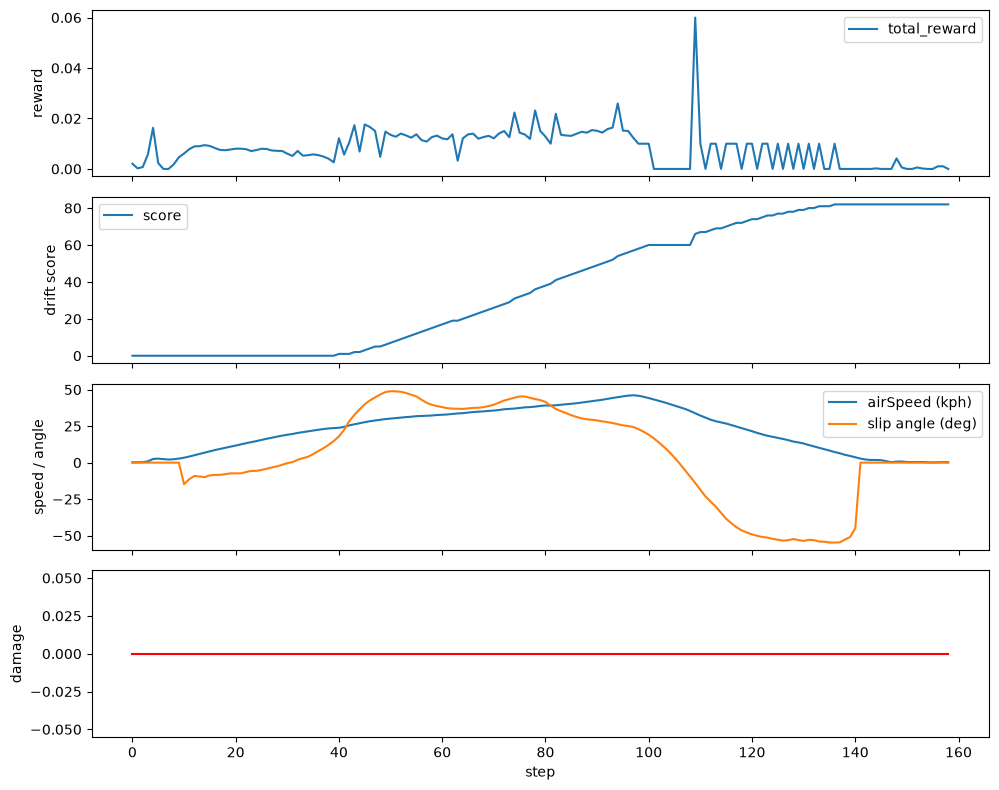

In [13]:
def ctrl_loop_init():
    global ego, electrics, damage, timer

    key = "Bridge15_C"
    ego.teleport(
        waypoints[key].pos, rot_quat=waypoints[key].rot
    )
    time.sleep(1.07)
    # pause physics / time
    beamng.control.pause()

beamng.queue_lua_command('settings.setValue("enableDriftFreeroamCruising", true)')
beamng.queue_lua_command('gameplay_drift_general.setContext("inFreeroam")')
ego.ai.set_mode("none")

previous = {}
previous["speed"] = 0.0
previous["score"] = 0.0
previous["damage"] = 0.0

failed = False

# per-iteration data collected for the end plot
hist = dict(
    total_reward=[], potential=[], score=[],
    damage=[], isDrifting=[], angle=[], airSpeed=[],
)

step = 0

# poll drift variables:
def ctrl_loop_hook():
    global ego, previous, failed, step

    # get the data for this frame
    ego.sensors.poll()
    drift = read_drift(beamng)

    # populate the dict with the relevant values for the reward function
    current = {}
    current["speed"] = drift["airSpeed"]
    current["score"] = drift["potentialScore"]
    current["damage"] = ego.sensors["damage"].get("damage", 0.0)
    
    total, c = compute_reward(current, previous)

    previous = current

    if not failed:
        failed, reason = check_failure(dmg)
        if failed:
            print(f"\nFAILED step {step}: {reason} (would end scenario)")

    hist["total_reward"].append(total)
    hist["potential"].append(drift["potentialScore"])
    hist["score"].append(current["score"])
    hist["damage"].append(previous["damage"])
    hist["isDrifting"].append(drift["isDrifting"])
    hist["angle"].append(drift["angle"] if drift["airSpeed"] > 3.0 else 0.0)
    hist["airSpeed"].append(drift["airSpeed"])

    step += 1

ctrl_loop()

%matplotlib inline

# one plot of the whole run, at the end
t = np.arange(len(hist["total_reward"]))
fig, axes = plt.subplots(4, 1, figsize=(10, 8), sharex=True)
axes[0].plot(t, hist["total_reward"], label="total_reward")
axes[0].set_ylabel("reward")
axes[0].legend()
axes[1].plot(t, hist["score"], label="score")
axes[1].set_ylabel("drift score")
axes[1].legend()
axes[2].plot(t, hist["airSpeed"], label="airSpeed (kph)")
axes[2].plot(t, hist["angle"], label="slip angle (deg)")
axes[2].set_ylabel("speed / angle")
axes[2].legend()
axes[3].plot(t, hist["damage"], color="red", label="damage")
axes[3].set_ylabel("damage")
axes[3].set_xlabel("step")
plt.tight_layout()
plt.show()


Again you can change the amount of time to pause `x` after teleporting in the `time.sleep(x)` call to get a totally different outcome, which may include damage too.

### Bird's Eye View (BEV) - distance and height map

A driver normally is in the driver seat, observing distances and heights visually, so why the choice for a BEV?  
A camera is usually better for detecting at longer distances, but requires more data to be processed.

This height map is more efficient for the amount of data used and it informs simply and efficiently about raised obstacles and the road structure.
It's not ruled out for a later iteration to process camera frames (instead or in addition) - my first idea was to have a camera pointed in the direction of travel (rotating continuously to counter the rotation of the vehicle).

Either way it seems like we will have to build our AI architecture to be multi modal - which means it must process diverse types of information, such as a number representing speed or this BEV which is an image that encodes heights and distances at the same time.

#### How does it work?

The sensor which provides heights and distances at the same time is the LIDAR sensor. It is a complicated sensor that spins around very fast (at a determined rate of rotations per second - Hz), firing laser light in all directions and times when the reflection hits it back to determine the distances for all directions, with every distance + direction building towards a `point cloud`, representing points in space. In BeamNG.tech this LIDAR sensor can be visualized and it is very interesting to watch - the next code block will add this sensor, if you want to see the point cloud in game, activate this with `is_visualised=True`.

In [14]:
# LiDAR: full 360-degree scan, attached to the ego car's roof
# We rotate the display / observation to the travel direction.
LIDAR_RES_V = 64        # vertical resolution (number of horizontal slices)
LIDAR_V_ANGLE = 26.9    # vertical aperture (deg)
LIDAR_HZ = 20           # rotation frequency (Hz)
LIDAR_MAX_DIST = 40.0   # max range (m)
LIDAR_DENSITY = 50      # point density (1 = dense, 100 = sparse)

lidar = Lidar(
    "roof",
    beamng,
    ego,                                   # attached to the car -> rides with it
    requested_update_time= 1.0/LIDAR_HZ,   # 20 Hz
    pos=(0.0, 0.0, 1.5),                   # on the roof, in vehicle space
    vertical_resolution=LIDAR_RES_V,
    vertical_angle=LIDAR_V_ANGLE,
    frequency=LIDAR_HZ,
    max_distance=LIDAR_MAX_DIST,
    density=LIDAR_DENSITY,
    is_360_mode=True,                      # MODE I: full 360 degrees
    is_rotate_mode=False,
    is_using_shared_memory=True,
    is_visualised=False,
    is_streaming=True,
)

print("lidar created:", lidar.name)


BB half extents (L, W, H): 1.8986 4.441 1.2445
lidar created: roof


#### How do we build our BEV with this data?

The top of the view was chosen to represent what's directly ahead of the travel direction (not the front!) of the car, because it's where a drifter would look and where the camera in the game looks - the obvious area to check while drifting. In other appliactions, this isn't needed because the front of the car usually points towards the travel direction.

BeamNG.tech has a debug mode for drifting which also helps to visually understand why travel direction is the important direction for drifting. Take it for a spin!

In [65]:
beamng.queue_lua_command('gameplay_drift_general.setDebug(true)')

This should also reveal a dynamic we'll need to counter - when there's no speed, the angle keeps pointing in random directions.

Since it's rather distracting, we should turn it off for now.

In [66]:
beamng.queue_lua_command('gameplay_drift_general.setDebug(false)')

In our BEV, the car (the LIDAR sensor to be precise) will land in the center and the maximum range displayed in every direction is the lidar range, normalized to the grid size `BEV_N`, in our case chosen to be 64, leading to 4096 values per frame (n*n).

The values (seen as brightness / intensity) represent the height of the highest point in the lidar point cloud, 


`TODO VERIFY` clamped to `[0, 1]` (0.5 = road level). The heights which are of importance are 1 meter below and above the road level, defined by `Z_LO` and `Z_HI`.

In [15]:
# --- vehicle-frame helpers (re-used by the display and the BEV grid) ---
def car_rotation(state):
    """Rotation matrix whose COLUMNS are the car's [forward, left, up] axes in
    world space, built from the (normalised) dir and up vectors."""
    d = np.asarray(state["dir"], float); d /= np.linalg.norm(d)
    u = np.asarray(state["up"], float);  u /= np.linalg.norm(u)
    l = np.cross(u, d)                     # left
    l /= np.linalg.norm(l)
    return np.stack([d, l, u], axis=1)     # columns [fwd, left, up]

def travel_slip(drift):
    """Travel-up rotation (rad) from the game's signed drift angle (deg)."""
    return float(np.deg2rad(drift.get("angle", 0.0)))

BEV_N = 64
Z_LO, Z_HI = -1.0, 1.0   # (m) road band: squeeze the scale so the raised divider pops

def lidar_bev(pc, state, drift, n=BEV_N, range_m=LIDAR_MAX_DIST):
    """
    Prepare a bird's eye view 2D matrix
    The car is in the center and the maximum range displayed in every direction is the lidar range, normalized to the grid size n
    The values (seen as brightness / intensity) represent the height of the highest point in the lidar point cloud, clamped to [0, 1] (0.5 = road level)
    
    Parameters
    ----------
    pc : np.ndarray, shape (N, 3)
        Lidar point cloud in world coordinates; each row is a point (x, y, z) - (fwd, left, up)       
    state : dict
        The car's current state, must contain "pos" (world position) and the orientation used by car_rotation
    drift : dict
        Drift telemetry from read_drift; must contain "angle", the game's signed drift angle in degrees (nose vs. direction of travel)       
    n : int, optional
        Grid size, the output is (n, n) cells (default is BEV_N = 64) 
    range_m : float, optional
        Half-extent of the grid in meters; it spans [-range_m, +range_m] around the car in both axes (default is LIDAR_MAX_DIST)
    """

    # Prepare a n * n 2D matrix which will represent the BEV, default BEV_N * BEV_N
    out = np.full((n, n), np.nan, np.float32)
    # return early if there are no lidar points
    if pc.size == 0:
        return out
    # get the car's rotation matrix relative to the world (axis)
    R = car_rotation(state)
    # subtract the car position from every point cloud dot relative to the car
    # to get the point cloud translated to be relative to the car
    # then rotate to match the car's rotation instead of the world's rotation
    p = (pc - np.asarray(state["pos"], float)) @ R   # [fwd, left, up]
    # split the points by axis
    x, y, z = p[:, 0], p[:, 1], p[:, 2]
    # obtain the drift angle and convert deg -> rad
    slip = travel_slip(drift)
    # pi/2 is 90 deg - meant to align the grid up axis to the car forward axis
    # the `slip` angle is subtracted to ensure that the direction of travel
    # is what finally represents the grid up axis in the BEV grid
    th = 0.5 * np.pi - slip
    # with the cos and sin of the angle, we can rotate every point on the (x,y) meaning (fwd,left) axis
    c, s = np.cos(th), np.sin(th)
    dx, dy = x * c - y * s, x * s + y * c
    # ix and iy are translations from physical distances in meters into the column and row
    # numbers in the BEV grid, rescaling into the BEV_N * BEV_N space, from lidar range
    ix = ((dx + range_m) * n / (2 * range_m)).astype(int)
    iy = ((dy + range_m) * n / (2 * range_m)).astype(int)
    # m is the mask for points that landed in the BEV_N * BEV_N space
    m = (ix >= 0) & (iy >= 0) & (ix < n) & (iy < n)
    # cell is the index which represents row and column with a single number
    # ex: for a 4x4 grid, index 12 would land in the last row and first column
    # this also flips the grid top to bottom (n-1-iy[m])
    cell = (n - 1 - iy[m]) * n + ix[m]
    # get the value of each dot in the BEV representing the height,
    # clamped to [0, 1] so the channel is bounded (0.5 = road level)
    h = np.clip((z[m] - Z_LO) / (Z_HI - Z_LO), 0.0, 1.0)
    # indices sorted low to high
    order = np.argsort(cell, kind="stable")
    # identify only the points in the grid where lidar points exist
    u, first = np.unique(cell[order], return_index=True)
    # update only those points with height information
    row, col = u // n, u % n
    out[row, col] = np.maximum.reduceat(h[order], first)
    return out

print("lidar_bev defined; obs:", (BEV_N, BEV_N))


lidar_bev defined; obs: (64, 64)


A camera is also created, just for debugging

In [16]:
# --- bird's-eye camera: static camera high above the car, looking straight
#     down. Static (not attached) so set_position/set_direction/set_up stick,
#     same pattern as the old hood camera. Used for the "game view" corner.
BIRD_ALT = 25.0
bird = Camera(
    "bird", beamng, None,
    requested_update_time=1.0/LIDAR_HZ,
    is_using_shared_memory=True, is_streaming=True,
    is_render_colours=True,
    resolution=(320, 320),
    pos=(0.0, 0.0, BIRD_ALT),
    dir=(0.0, 0.0, -1.0),
    up=(1.0, 0.0, 0.0),
    field_of_view_y=90,
    near_far_planes=(1.0, 100.0),
    is_static=True,
)

def follow_bird(state):
    """Keep the bird camera above the car, with the TRAVEL direction up in the
    image - matching the scatter/BEV panels (which rotate to velocity, not to
    the car's nose; the two differ by the slip angle while drifting)."""
    pos = np.asarray(state["pos"], float)
    vel = np.asarray(state["vel"], float)
    v = np.array([vel[0], vel[1], 0.0])
    if np.linalg.norm(v) < 1.0:            # stopped: travel dir undefined
        d = np.asarray(state["dir"], float)
        v = np.array([d[0], d[1], 0.0])
    v /= np.linalg.norm(v)
    bird.set_position(tuple(pos + np.array([0.0, 0.0, BIRD_ALT])))
    bird.set_direction((0.0, 0.0, -1.0))
    bird.set_up(tuple(v))

print("bird camera created")

bird camera created


##### Plotting the LIDAR birds-eye view, chart top aligned to car travel direction

points: 43609, valid cells: 1570


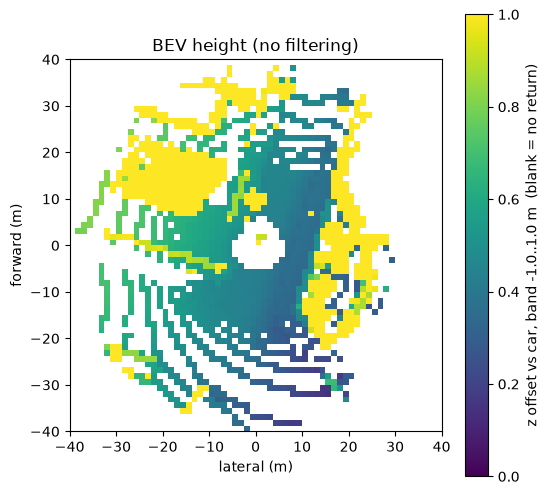

In [17]:
# accelerate to have a proper direction of travel
ego.control(throttle=1.0)
time.sleep(0.5)
ego.control(throttle=0.0)

# get the point cloud from the lidar sensor
ego.sensors.poll()
pc = lidar.poll()["pointCloud"]
drift = read_drift(beamng)
bev = lidar_bev(pc, ego.state, drift)
print(f"points: {pc.shape[0]}, valid cells: {int(np.count_nonzero(~np.isnan(bev)))}")

# plot the bev
plt.figure(figsize=(6, 6))
plt.imshow(bev, cmap="viridis", vmin=0.0, vmax=1.0,
           extent=(-LIDAR_MAX_DIST, LIDAR_MAX_DIST, -LIDAR_MAX_DIST, LIDAR_MAX_DIST),
           interpolation="nearest")
plt.title("BEV height (no filtering)")
plt.xlabel("lateral (m)")
plt.ylabel("forward (m)")
plt.colorbar(label=f"z offset vs car, band {Z_LO}..{Z_HI} m  (blank = no return)")
plt.show()


##### Generates an AVI mjpeg of the BEV height map plus an actual camera, for debugging

In [18]:
# --- recording: write each frame to a temp folder, merge to an MJPEG .avi at the end ---

def start_recording(prefix="drift"):
    """Create a temp frame folder. Returns (folder, save_mjpeg)."""
    d = tempfile.mkdtemp(prefix=prefix + "-frames-")
    print("frames ->", d)

    def save_mjpeg(path=None, fps=5):
        files = sorted(glob.glob(os.path.join(d, "frame_*.png")))
        if not files:
            print("no frames to save")
            return None
        
        out = path or os.path.join(d, "recording.avi")
        h, w = cv2.imread(files[0]).shape[:2]
        writer = cv2.VideoWriter(out, cv2.VideoWriter_fourcc(*"MJPG"), fps, (w, h))
        for f in files:
            writer.write(cv2.imread(f))
        writer.release()
        for f in files:
            os.remove(f)
        print("mjpeg ->", out, f"({len(files)} frames)")
        return out

    return d, save_mjpeg

frames_dir, save_mjpeg = start_recording()


frames -> /tmp/drift-frames-k8j1jyh7


mjpeg -> /tmp/drift-frames-k8j1jyh7/recording.avi (30 frames)
video: /tmp/drift-frames-k8j1jyh7/recording.avi


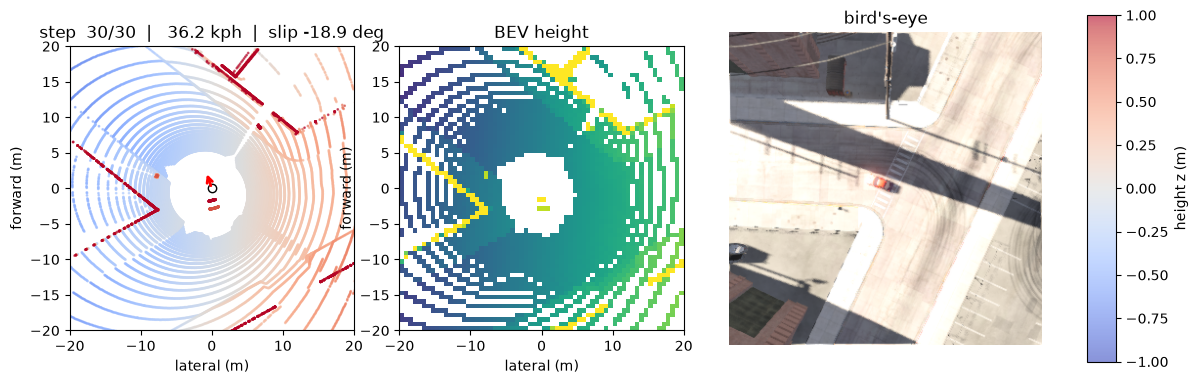

In [22]:
%matplotlib inline

DEBUG_ITERS = 30
RANGE_M = 20.0   # display radius (m)

# scatter (height z) | BEV height | game(bird) | colorbar
fig, (ax, axb, axg, cax) = plt.subplots(1, 4, figsize=(13.5, 4.5),
    gridspec_kw={"width_ratios": [3, 3, 3.3, 0.3]})

for step in range(1, DEBUG_ITERS + 1):
    ego.sensors.poll()
    state = ego.state
    drift = read_drift(beamng)
    pc = lidar.poll()["pointCloud"]

    ax.clear(); axb.clear(); axg.clear(); cax.clear()
    slip = travel_slip(drift)
    if pc.size:
        R = car_rotation(state)
        p_veh = (pc - np.asarray(state["pos"], float)) @ R   # [fwd, left, up]
        x, y, z = p_veh[:, 0], p_veh[:, 1], p_veh[:, 2]
        th = 0.5 * np.pi - slip
        c, s = np.cos(th), np.sin(th)
        dx, dy = x * c - y * s, x * s + y * c
        sc = ax.scatter(dx, dy, c=z, cmap="coolwarm", s=1, alpha=0.6,
                        vmin=Z_LO, vmax=Z_HI)
        fig.colorbar(sc, cax=cax, label="height z (m)")
        nose = np.array([np.sin(slip), np.cos(slip)])
        ax.plot(0, 0, "o", color="white", ms=6, mec="black", zorder=6)
        ax.annotate("", xy=2.5 * nose, xytext=(0, 0),
                    arrowprops=dict(arrowstyle="->", color="red", lw=2), zorder=6)
        bev = lidar_bev(pc, state, drift, n=BEV_N, range_m=RANGE_M)
        ext = (-RANGE_M, RANGE_M, -RANGE_M, RANGE_M)
        axb.imshow(bev, cmap="viridis", vmin=0, vmax=1,
                   extent=ext, interpolation="nearest")
    kph = drift["airSpeed"]
    for a in (ax, axb):
        a.set_xlim(-RANGE_M, RANGE_M); a.set_ylim(-RANGE_M, RANGE_M); a.set_aspect("equal")
    axg.axis("off")
    follow_bird(state)
    rb = bird.poll()
    if rb is not None and rb.get("colour") is not None:
        axg.imshow(rb["colour"])
    axg.set_title("bird's-eye")
    ax.set_title(f"step {step:3d}/{DEBUG_ITERS}  |  {kph:5.1f} kph  |  slip {np.rad2deg(slip):5.1f} deg")
    ax.set_xlabel("lateral (m)"); ax.set_ylabel("forward (m)")
    axb.set_title("BEV height")
    axb.set_xlabel("lateral (m)"); axb.set_ylabel("forward (m)")

    fig.savefig(os.path.join(frames_dir, f"frame_{step:04d}.png"), dpi=70)
    time.sleep(1 / 20)

video_path = save_mjpeg()
if video_path:
    print("video:", video_path)


In this image you can see that the car may be almost correctly aligned to the street, however it is actually travelling where the top of the image points (towards the curb), highlighting that it is much more important to know the travel direction than where the car's pointing, to consistently place obstacles in the same image region.

This placement choice comes from the intuition that having the obstacles always in the same region will help the AI to understand better / faster what to do with the information.

### Next steps

Next we'll explore how we can set up the environment and how this environment is defined and linked with different libraries in python.